# Do deep throwers have dependable “best zones”?
## tl;dr
Across 22,386 regular-season hucks in the 2021–2026 export, this test does **not establish reliable player-specific best release zones**.

Among 48 testable players, the average chosen-zone advantage fell from **12.7 percentage points in 2021–2025 to 0.7 points in 2026**. The 2026 player-bootstrap interval is **−9.1 to +10.2 points**. Personalized zone effects did not improve held-out completion prediction beyond shared zone and coarse throw geometry.

A more useful near-term direction is predicting **whether a player attempts a huck**. Adding player history to league field-position tendencies reduced 2026 prediction error by **3.1%**, across **6,173 passes by 44 players** released from Y20–60. This is a modest forecasting improvement, not a 3.1-point increase in completion or proof that a particular defensive tactic works. Personal zone interactions added no reliable further improvement.

The source is the October 12 exported snapshot; October 24 live season totals match, but row contents were not refetched. This is an exploratory historical check, including a previously inspected 2026 season.

## Context & Methods
**Coaching decision:** Is there evidence to recommend a different preferred release zone for each deep thrower, or is a simpler scouting view more defensible?

- Primary comparison: train on 2021–2025 regular seasons, evaluate 2026. Expanding-history checks evaluate 2022–2025. Training sets and players overlap across checks.
- Huck: forward gain strictly greater than 30 yards **and** straight-line distance strictly greater than 40 yards. Stalls are excluded. Completion means no recorded turnover; drops are incomplete.
- Best-zone selection: at least 40 prior hucks and two zones with at least 10 prior attempts. Choose the highest earlier completion rate. Evaluate against all other zones for that player in 2026. A player must have a later attempt both inside and outside the chosen zone for a paired comparison.
- The main gap gives each player equal weight. Pooled percentages shown separately give more weight to players with more throws; they need not have the same gap.
- Prediction models use fixed penalized binomial regression. Shared geometry adjusts for flight-length and forward-gain categories and an end-zone endpoint. A player-by-zone term asks whether personal zones add predictive value beyond those baselines. Penalties are fixed, not tuned on 2026.
- Attempt prediction uses passes released at Y20 to less than Y60, with additional 10-yard release-depth adjustment. It does not use the future receiver location to predict the attempt decision.
- Intervals: 5,000 bootstrap samples of entire players for the zone gap; entire games and, separately, players for prediction-error differences. Intervals are omitted with fewer than 10 clusters. These intervals are conditional on training and do not capture all crossed dependence.

### Key Assumptions
Source coordinates represent offense moving toward Y120, as specified by the data owner. Recomputed geometry matches the supplied differences and distances. Stable source player IDs are kept; same-name IDs are not automatically merged. An unclassified 2021 game is excluded.

Association is not causation. Receiver movement, marking, pressure, wind, stall count, role and team changes can affect results. Endpoint geometry is a retrospective difficulty adjustment for completion, not information available before release. Failure of these fixed models does not prove that no player has a real zone advantage.

In [1]:
from pathlib import Path
import contextlib, io, json, sys
import pandas as pd

project = next(p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / 'analysis/multiseason_release_validation.py').exists())
sys.path.insert(0, str(project / 'analysis'))
import multiseason_release_validation as study
import multiseason_release_checks as checks

RERUN_ANALYSIS = True  # Set False only to inspect the saved, hash-identified result.
if RERUN_ANALYSIS:
    with contextlib.redirect_stdout(io.StringIO()):
        result = study.run()
else:
    result = json.loads((project / 'analysis/multiseason_release_validation.json').read_text())
primary = result['studies'][-1]
print('Primary test: history from 2021–2025 → outcomes in 2026.')
print('Source: data/database-exports/2026-10-12/{throws,games,players}.csv')
print('Live count receipt: data/database-metadata/2026-10-24/live-season-coverage.json')

Primary test: history from 2021–2025 → outcomes in 2026.
Source: data/database-exports/2026-10-12/{throws,games,players}.csv
Live count receipt: data/database-metadata/2026-10-24/live-season-coverage.json


## Data
The analysis reads all three full exports, verifies their recorded SHA-256 hashes, checks one row per game and per game/throw ID, then filters regular-season, identified, nonstall passes with valid geometry. No source rows or website data are edited. Game and throw counts also reconcile with the saved live DBeaver result.

In [2]:
coverage = pd.DataFrame(result['quality']['seasonRows'])
coverage[['season', 'analysisGames', 'analysisThrows', 'hucks', 'completedHucks']].rename(columns={
    'season':'Season', 'analysisGames':'Games', 'analysisThrows':'Located passes',
    'hucks':'Huck attempts', 'completedHucks':'Completed hucks'})

,Season,Games,Located passes,Huck attempts,Completed hucks
0,2021,127,67935,3333,2043
1,2022,150,79562,4199,2616
2,2023,144,78504,3750,2292
3,2024,144,79989,3847,2353
4,2025,144,77975,3750,2323
5,2026,131,72590,3507,2209


In [3]:
validation = checks.check()  # Independent csv-reader implementation of counts and zone selection.
assert sum(row['analysisThrows'] for row in result['quality']['seasonRows']) == 456555
assert validation['independentlyMatchedHucks'] == 22386
print('Independent recalculation matched every seasonal huck/completion count and all 48 selected player-zone identities.')
print('2026 chosen zones: 139 / 201 complete; other zones: 438 / 660 complete.')
print('No duplicate game/throw keys or orphan GameIDs; all 490,685 comparable geometry rows matched.')
print('Excluded: 481 throws in an unclassified 2021 game. Three missing source coordinates belong to already-excluded unnamed throwers.')
print('Identity: source IDs preserved; same-name IDs are not merged.')

Independent recalculation matched every seasonal huck/completion count and all 48 selected player-zone identities.
2026 chosen zones: 139 / 201 complete; other zones: 438 / 660 complete.
No duplicate game/throw keys or orphan GameIDs; all 490,685 comparable geometry rows matched.
Excluded: 481 throws in an unclassified 2021 game. Three missing source coordinates belong to already-excluded unnamed throwers.
Identity: source IDs preserved; same-name IDs are not merged.


## Results
### 1. Earlier best zones did not show a dependable later advantage
The same 48 players and historically selected zones are used in both periods. The historical advantage is inflated by selecting the best-looking earlier zone; the later season is the relevant test. Of 97 historically eligible players, 48 had a 2026 attempt both inside and outside the selected zone.

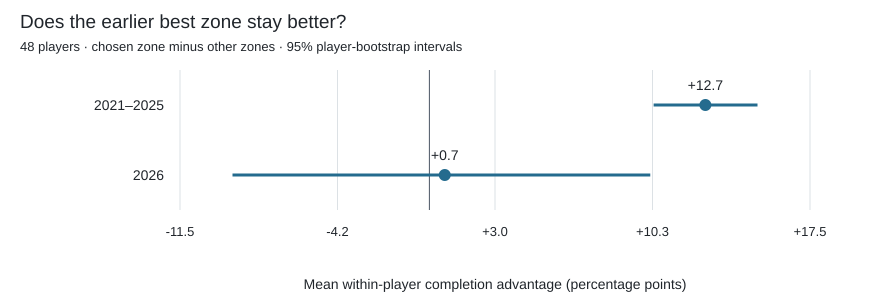

In [4]:
from html import escape
import math

class SVGFigure:
    def __init__(self, value): self.value = value
    def _repr_svg_(self): return self.value

def interval_figure(rows, title, axis, subtitle):
    # Small, directly labeled vector figures, embedded in the saved notebook.
    width, left, right, row_h = 880, 180, 70, 70
    top, bottom = 90, 75
    height = top + row_h * len(rows) + bottom
    bounds = [0] + [v for row in rows for v in (row['low'], row['high'])]
    lo, hi = min(bounds), max(bounds)
    span = max(hi-lo, 1)
    lo -= span*.1; hi += span*.1
    x = lambda value: left + (value-lo)/(hi-lo)*(width-left-right)
    parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}" role="img" aria-label="{escape(title)}">',
             f'<rect width="{width}" height="{height}" fill="#ffffff"/>',
             '<g font-family="Arial,sans-serif" fill="#20252b">',
             f'<text x="20" y="28" font-size="19">{escape(title)}</text>',
             f'<text x="20" y="51" font-size="13">{escape(subtitle)}</text>']
    plot_bottom = top + row_h*len(rows)-20
    for i in range(5):
        value = lo+(hi-lo)*i/4
        xx=x(value)
        parts += [f'<line x1="{xx}" y1="{top-20}" x2="{xx}" y2="{plot_bottom}" stroke="#dce1e5"/>',
                  f'<text x="{xx}" y="{plot_bottom+26}" text-anchor="middle" font-size="13">{value:+.1f}</text>']
    parts += [f'<line x1="{x(0)}" y1="{top-20}" x2="{x(0)}" y2="{plot_bottom}" stroke="#4b5563"/>']
    for i,row in enumerate(rows):
        yy=top+i*row_h+15
        parts += [f'<text x="{left-16}" y="{yy+5}" text-anchor="end" font-size="14">{escape(row["label"])}</text>',
                  f'<line x1="{x(row["low"])}" y1="{yy}" x2="{x(row["high"])}" y2="{yy}" stroke="#246b8e" stroke-width="3"/>',
                  f'<circle cx="{x(row["mean"])}" cy="{yy}" r="6" fill="#246b8e"/>',
                  f'<text x="{x(row["mean"])}" y="{yy-15}" text-anchor="middle" font-size="14">{row["mean"]:+.1f}</text>']
    parts += [f'<text x="{(left+width-right)/2}" y="{height-16}" text-anchor="middle" font-size="14">{escape(axis)}</text>', '</g></svg>']
    return SVGFigure(''.join(parts))

b = primary['bestCompletionZone']
zone_plot_rows = [dict(label=label, mean=b[key]['mean']*100,
                      low=b[key]['ci95'][0]*100, high=b[key]['ci95'][1]*100)
                  for label,key in [('2021–2025','trainPlayerGap'),('2026','testPlayerGap')]]
interval_figure(zone_plot_rows, 'Does the earlier best zone stay better?',
                'Mean within-player completion advantage (percentage points)',
                '48 players · chosen zone minus other zones · 95% player-bootstrap intervals')

**Interpretation:** The 2026 average gap is +0.7 points, with a −9.1 to +10.2 interval. There is insufficient precision to recommend each player’s earlier best box as a reliably better location. This is not evidence that moving a player there would improve completion.

The pooled 2026 rates are 69.2% (139/201) in the selected zones versus 66.4% (438/660) elsewhere. Those percentages weight throws; the chart weights players equally. Twenty-six players had a positive later gap, four tied, and eighteen had a negative gap.

In [5]:
example_rows = sorted((r for r in b['rows'] if r['test']['gap'] is not None),
    key=lambda r: -(r['test']['chosen']['attempts']+r['test']['other']['attempts']))[:10]
examples = []
for row in example_rows:
    output = {'Player':row['name'], 'Earlier chosen zone':row['zoneLabel']}
    for period, label in [('train','2021–25'),('test','2026')]:
        for group, desc in [('chosen','chosen zone'),('other','elsewhere')]:
            c=row[period][group]
            output[f'{label}: {desc}']=f"{c['successes']}/{c['attempts']} ({c['rate']:.0%})"
    examples.append(output)
pd.DataFrame(examples)

,Player,Earlier chosen zone,2021–25: chosen zone,2021–25: elsewhere,2026: chosen zone,2026: elsewhere
0,Jake Felton,"Right sideline, 20–60 yd",22/31 (71%),83/156 (53%),8/15 (53%),29/47 (62%)
1,Chad Yorgason,"Center, 40–60 yd",10/12 (83%),34/47 (72%),17/21 (81%),15/20 (75%)
2,Alex Atkins,"Left sideline, 20–60 yd",8/10 (80%),61/87 (70%),3/4 (75%),25/31 (81%)
3,Ben Thoennes,"Center, 40–60 yd",20/27 (74%),52/92 (57%),8/9 (89%),18/26 (69%)
4,Austin Taylor,"Left sideline, 20–60 yd",12/14 (86%),115/155 (74%),1/1 (100%),26/33 (79%)
5,Kyle Henke,"Center, 60–80 yd",10/12 (83%),58/99 (59%),1/1 (100%),22/28 (79%)
6,Christophe Tremblay-Joncas,"Center, 40–60 yd",19/26 (73%),26/38 (68%),5/9 (56%),11/19 (58%)
7,Matt Miller,"Center, 40–60 yd",16/18 (89%),35/57 (61%),4/6 (67%),14/22 (64%)
8,David Barram,"Center, 20–40 yd",18/27 (67%),31/57 (54%),11/12 (92%),8/15 (53%)
9,AJ Merriman,"Right sideline, 20–60 yd",10/12 (83%),17/29 (59%),2/6 (33%),12/19 (63%)


Examples are ordered by 2026 huck volume among testable players, not by how favorable their result looks. Jake Felton’s earlier right-side advantage did not persist; Chad Yorgason’s center-zone comparison remained positive. Small later cells, including Alex Atkins’s four chosen-zone attempts, cannot support strong player-level conclusions.

### 2. Personal completion zones did not improve prediction
Lower Brier error means more accurate probabilities. Compare the same held-out throws under each model. The geometry models include receiver endpoints retrospectively, so this is a difficulty-adjusted association check rather than a pre-throw coaching forecast.

In [6]:
prediction_rows=[]
for s in result['studies'][1:]:
    p=s['completionPrediction']; c=p['comparisons']['personalGeometryMinusSharedGeometry']
    prediction_rows.append({'Test season':s['testSeason'],'Players':p['testPlayers'],'Hucks':p['testEvents'],
        'Shared geometry Brier':round(p['models']['sharedGeometry']['brier'],6),
        'Add personal zone Brier':round(p['models']['personalGeometry']['brier'],6),
        'Error change (%)':round(c['relativeErrorChangePct'],2),
        '95% game CI, error difference':str([round(v,5) for v in c['gameBootstrap']['ci95']])})
pd.DataFrame(prediction_rows)

,Test season,Players,Hucks,Shared geometry Brier,Add personal zone Brier,Error change (%),"95% game CI, error difference"
0,2023,32,781,0.226410,0.228338,0.85,"[-0.00076, 0.00476]"
1,2024,41,797,0.233289,0.235473,0.94,"[-0.00071, 0.00519]"
2,2025,51,964,0.232904,0.233579,0.29,"[-0.00171, 0.003]"
3,2026,66,1012,0.219848,0.220012,0.07,"[-0.00223, 0.0026]"


Personal zone effects did not reduce completion error in any of the 2023–2026 checks; each interval includes zero. The 2022 cohort has only two eligible returning players and is too small to support a league conclusion. Using only 2024–2025 history or a broader 10-prior-huck prediction cohort also did not establish an improvement. These are overlapping historical checks, not independent experiments.

### 3. A stronger alternative: forecast huck attempts
Here the outcome is whether any located, nonstall pass becomes a huck. Compare a league field-position model with the same model plus each player’s overall prior tendency. The release window is Y20 to less than Y60; both models include shared zones and 10-yard release depth. This controls the obvious inability to gain 30 yards near the end zone.

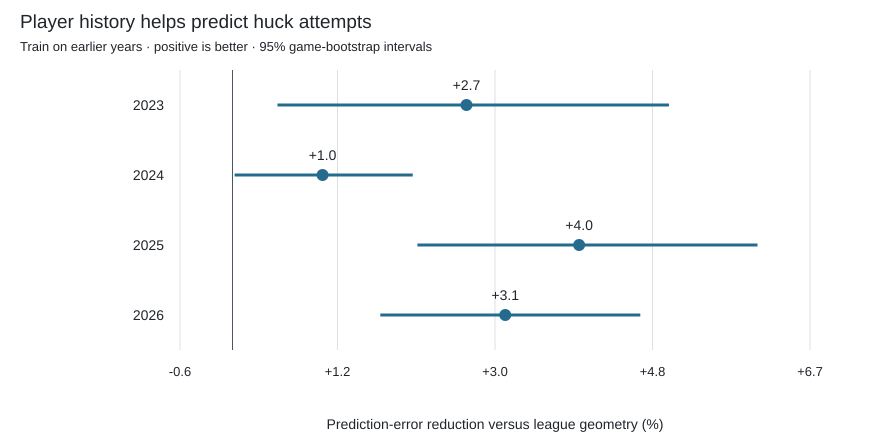

In [7]:
attempt_plot_rows=[]
for s in result['studies'][1:]:
    p=s['attemptPredictionY20_60']
    c=p['comparisons']['sharedGeometryMinusLeagueGeometry']
    baseline=p['models']['leagueGeometry']['brier']
    low,high=c['gameBootstrap']['ci95']
    attempt_plot_rows.append({'label':str(s['testSeason']), 'mean':-c['relativeErrorChangePct'],
                              'low':-100*high/baseline, 'high':-100*low/baseline})
interval_figure(attempt_plot_rows, 'Player history helps predict huck attempts',
                'Prediction-error reduction versus league geometry (%)',
                'Train on earlier years · positive is better · 95% game-bootstrap intervals')

In [8]:
attempt_rows=[]
for s in result['studies'][1:]:
    p=s['attemptPredictionY20_60']
    attempt_rows.append({'Test season':s['testSeason'], 'Players':p['testPlayers'],
        'Located passes':p['testEvents'],'Huck attempts':p['testSuccesses'],
        'League geometry Brier':round(p['models']['leagueGeometry']['brier'],6),
        'Add player history Brier':round(p['models']['sharedGeometry']['brier'],6),
        'Add personal zone Brier':round(p['models']['personalGeometry']['brier'],6)})
pd.DataFrame(attempt_rows)

,Test season,Players,Located passes,Huck attempts,League geometry Brier,Add player history Brier,Add personal zone Brier
0,2023,11,2157,224,0.093688,0.091157,0.091748
1,2024,31,5149,467,0.082175,0.081321,0.081267
2,2025,35,5260,544,0.093300,0.089566,0.090354
3,2026,44,6173,590,0.086515,0.083790,0.083986


**Interpretation:** The 2026 improvement is modest but survives both game- and player-level resampling. The broader 10-prior-huck cohort gives a 2.0% error reduction across 17,586 passes by 188 players. More detailed personal-zone terms add no dependable benefit. The evidence supports general player propensity plus shared field context better than unique player-zone archetypes.

## Takeaways
- Keep the current field maps as descriptive scouting summaries, with attempts and completions visible. Avoid labeling the highest observed box a validated personal strength.
- Prioritize the question **“Who is likely to huck from this field position?”** using player history plus general field patterns. This can prioritize film review and prepare defenders to anticipate deep attempts.
- Do not infer that denying a particular box will reduce goals, or that a completion percentage captures thrower skill alone. Those coaching claims need additional evidence.
- A subsequent validation could examine recent team roles and incoming-pass setups. That is a next question, not a result of this analysis.

All computations, exclusions, model specifications, sensitivity checks and per-player results are saved in `analysis/multiseason_release_validation.py` and `.json`. The independent count check is `analysis/multiseason_release_checks.py`. This notebook executes without database access given the three original CSVs and Python with numpy and pandas.